# Digit Recognizer with PyTorch

**Author:** Estelle Arnander · **Kaggle username:** estellearnander03

**Objective:** classify 28 x 28 grayscale handwritten digits (0 to 9) from the Kaggle Digit Recognizer competition.
We train an MLP baseline, a convolutional neural network (CNN) and improved CNNs, compare them on a hold-out
validation set and submit the best predictions to Kaggle.

All reusable code lives in the `digit_recognizer` package (`src/digit_recognizer/`). This notebook only imports it,
runs the experiments and shows the results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from digit_recognizer import (
    DigitDataset,
    check_data,
    compute_mean_std,
    get_device,
    load_test,
    load_train,
    make_loaders,
    set_seed,
    split_train_val,
)

SEED = 42
set_seed(SEED)
device = get_device()
print("Device:", device)

Device: mps


## 1. Data

### 1.1 Paths

The project root is the folder that contains `pyproject.toml`. Depending on the editor, the notebook runs either
from `notebooks/` or from the project root, so we check both.

In [2]:
if (Path.cwd() / "pyproject.toml").exists():
    project_root = Path.cwd()
else:
    project_root = Path.cwd().parents[0]

data_dir = project_root / "data"
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)
print("Project root:", project_root)

Project root: /Users/estellearnander/sem5/AI/digit-recognizer


### 1.2 Load and check the data

`check_data` confirms the expected shapes (42,000 x 785 and 28,000 x 784), that `label` is the first column,
that labels are 0 to 9, that pixels are 0 to 255 and that there are no missing values.

In [3]:
train_df = load_train(data_dir / "train.csv")
test_df = load_test(data_dir / "test.csv")

print("train.csv:", train_df.shape)
print("test.csv: ", test_df.shape)
print("Checks passed:", check_data(train_df, test_df))
train_df.iloc[:5, :8]

train.csv: (42000, 785)
test.csv:  (28000, 784)
Checks passed: True


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6
0,1,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


### 1.3 Train / validation split and normalisation

We keep a stratified 90/10 hold-out split with a fixed seed, so every model is evaluated on exactly the same
4,200 validation images and each class keeps the same proportion in both parts.

Pixels are scaled to [0, 1] and then normalised with the mean and standard deviation of the **training split only**.
Computing them on all the data would let validation information leak into preprocessing.

In [4]:
X_train, X_val, y_train, y_val = split_train_val(train_df, val_size=0.1, seed=SEED)
mean, std = compute_mean_std(X_train)

print("Training images:  ", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print(f"Training mean = {mean:.4f}, std = {std:.4f}")

Training images:   37800
Validation images: 4200
Training mean = 0.1310, std = 0.3085


### 1.4 Dataset and DataLoader

`DigitDataset` reshapes each row of 784 pixels to an image of shape `[1, 28, 28]` (1 channel, height, width).
The DataLoader groups images into batches of shape `[B, 1, 28, 28]`, the format a PyTorch CNN expects.

In [5]:
train_ds = DigitDataset(X_train, y_train, mean, std)
val_ds = DigitDataset(X_val, y_val, mean, std)
train_loader, val_loader = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)

images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), images.dtype)
print("Label batch:", tuple(labels.shape), labels.dtype)
print(f"Pixel values after normalisation: min {images.min():.2f}, max {images.max():.2f}")

Image batch: (128, 1, 28, 28) torch.float32
Label batch: (128,) torch.int64
Pixel values after normalisation: min -0.42, max 2.82


### 1.5 Look at the data

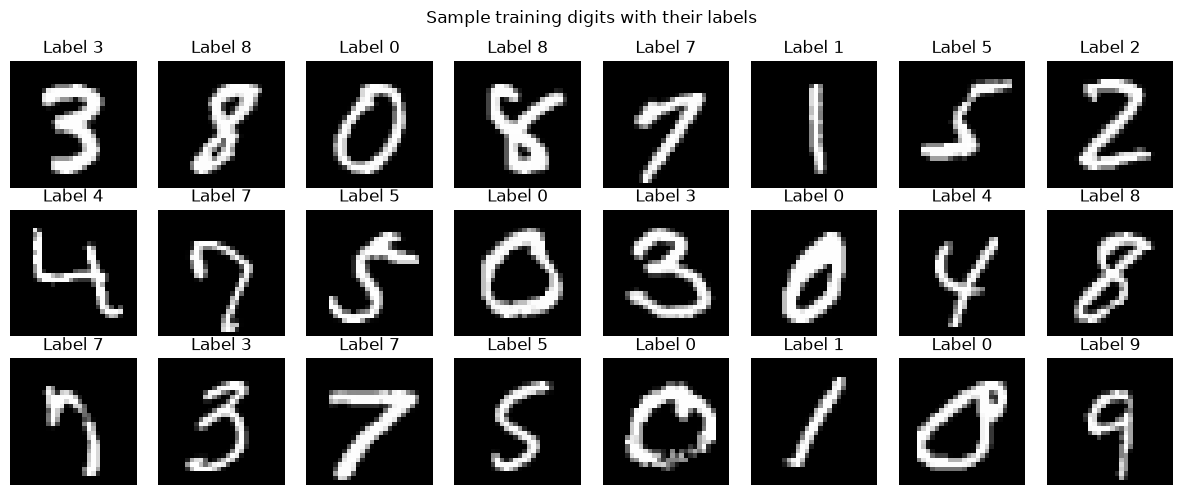

In [6]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, i in zip(axes.flat, range(24)):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label {y_train[i]}")
    ax.axis("off")
fig.suptitle("Sample training digits with their labels")
plt.tight_layout()
plt.savefig(results_dir / "sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

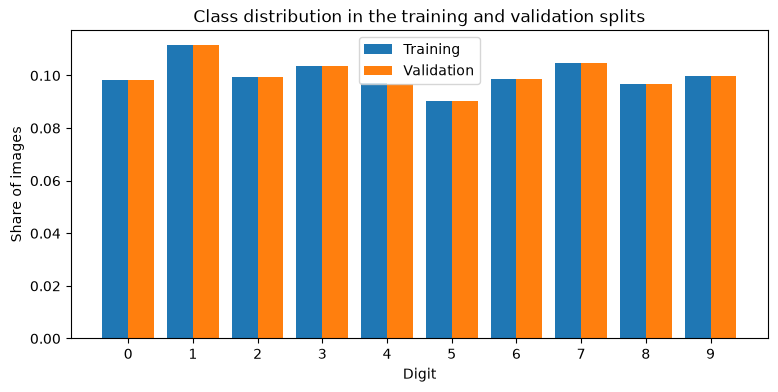

Training counts:   [3719 4216 3759 3916 3665 3415 3723 3961 3657 3769]
Validation counts: [413 468 418 435 407 380 414 440 406 419]


In [7]:
classes = np.arange(10)
train_counts = np.bincount(y_train, minlength=10)
val_counts = np.bincount(y_val, minlength=10)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(classes - 0.2, train_counts / train_counts.sum(), width=0.4, label="Training")
ax.bar(classes + 0.2, val_counts / val_counts.sum(), width=0.4, label="Validation")
ax.set_xticks(classes)
ax.set_xlabel("Digit")
ax.set_ylabel("Share of images")
ax.set_title("Class distribution in the training and validation splits")
ax.legend()
plt.savefig(results_dir / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Training counts:  ", train_counts)
print("Validation counts:", val_counts)

**Observations**

- Stratification works: every digit has the same share of images in the training and validation splits.
- The classes are roughly balanced. The most common digit (1, with 4,216 training images) appears about
  1.2 times as often as the least common (5, with 3,415). With an imbalance this mild, accuracy is a fair
  metric (it is also the Kaggle metric) and no class weighting is needed in the loss.
- After normalisation the black background has the value -0.42 and the brightest strokes 2.82.

## 2. MLP baseline

The baseline is a multilayer perceptron: the 28 x 28 image is flattened into a vector of 784 pixels and passed
through two fully connected hidden layers (256 and 128 neurons, ReLU, dropout 0.2) to 10 output logits.

Flattening throws away the spatial layout of the image: the MLP does not know which pixels are neighbours, so it
has to learn every spatial pattern from scratch. This is the weakness the CNN in section 3 addresses with its
built-in assumptions of locality and translation invariance (lecture 8).

All models in this notebook use the same training setup so their results are comparable: Adam with learning rate
0.001, cross-entropy loss on the logits, batch size 128 and 15 epochs. After training, each model keeps the weights
of the epoch with the best validation accuracy. Each model also gets its own freshly created training DataLoader,
so its shuffle order is the same no matter which cells ran before it.

In [8]:
from digit_recognizer import MLP, count_parameters, fit, plot_history

EPOCHS = 15
results = {}

set_seed(SEED)
mlp = MLP(hidden_dims=(256, 128), dropout=0.2)
print(mlp)
print("Trainable parameters:", count_parameters(mlp))

logits = mlp(images[:4])
print("Output shape for 4 images:", tuple(logits.shape))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146
Output shape for 4 images: (4, 10)


In [9]:
set_seed(SEED)
mlp_train_loader, _ = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
mlp_history = fit(mlp, mlp_train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["MLP"] = {"history": mlp_history, "params": count_parameters(mlp)}

Epoch  1/15 | train loss 0.3847 acc 0.8817 | val loss 0.1712 acc 0.9469
Epoch  2/15 | train loss 0.1652 acc 0.9504 | val loss 0.1362 acc 0.9602
Epoch  3/15 | train loss 0.1251 acc 0.9606 | val loss 0.1046 acc 0.9676
Epoch  4/15 | train loss 0.0976 acc 0.9697 | val loss 0.0967 acc 0.9705
Epoch  5/15 | train loss 0.0800 acc 0.9742 | val loss 0.0925 acc 0.9729
Epoch  6/15 | train loss 0.0696 acc 0.9775 | val loss 0.0863 acc 0.9750
Epoch  7/15 | train loss 0.0638 acc 0.9787 | val loss 0.0835 acc 0.9752
Epoch  8/15 | train loss 0.0556 acc 0.9822 | val loss 0.0814 acc 0.9771
Epoch  9/15 | train loss 0.0466 acc 0.9840 | val loss 0.0817 acc 0.9760
Epoch 10/15 | train loss 0.0439 acc 0.9863 | val loss 0.0876 acc 0.9776
Epoch 11/15 | train loss 0.0376 acc 0.9874 | val loss 0.0862 acc 0.9771
Epoch 12/15 | train loss 0.0376 acc 0.9873 | val loss 0.0873 acc 0.9786
Epoch 13/15 | train loss 0.0339 acc 0.9888 | val loss 0.0890 acc 0.9764
Epoch 14/15 | train loss 0.0311 acc 0.9895 | val loss 0.0857 acc

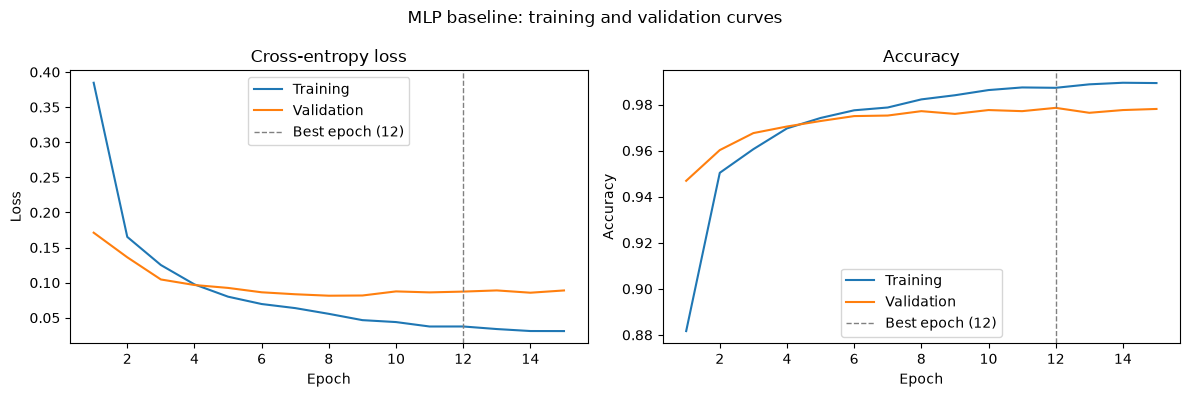

MLP best validation accuracy: 0.9786 (epoch 12)


In [10]:
plot_history(mlp_history, "MLP baseline: training and validation curves",
             save_path=results_dir / "mlp_curves.png")
print(f"MLP best validation accuracy: {mlp_history['best_val_acc']:.4f} (epoch {mlp_history['best_epoch']})")

**Observations**

- The MLP reaches **0.9786** validation accuracy (90 errors out of 4,200), above the 0.97 reference for a simple
  MLP given in the instructions.
- Overfitting starts around epoch 8. Validation loss is lowest there (0.0814) and then goes up to about 0.089,
  while training loss keeps falling to 0.031. The network starts to memorise training images instead of learning
  patterns that generalise.
- Validation loss and accuracy disagree on the best epoch (8 for loss, 12 for accuracy). Accuracy only counts right
  or wrong answers, while loss also penalises low confidence. We select on accuracy because it is the Kaggle metric.
- Validation accuracy moves by up to about 0.2 points from one epoch to the next (for example 0.9786, 0.9764, 0.9776).
  With 4,200 validation images at about 98 to 99% accuracy, the 95% uncertainty of one accuracy value is about
  ±0.3 points, or about ±13 images. Differences between models smaller than that should not be treated as real.
- Every model is trained with a fixed seed and its own freshly created DataLoader, so its result does not depend on
  which cells ran before it. An earlier version shared one DataLoader between all models. Adding a cell then changed
  the shuffle order, and therefore the results, of every model trained after it.

## 3. Convolutional neural network

The CNN keeps the image as a 28 x 28 grid. Each convolution slides small 3 x 3 filters over the image, so it looks
at neighbouring pixels together (locality) and reuses the same filter at every position (translation invariance).
These built-in assumptions (the inductive bias from lecture 8) mean the network does not have to learn spatial
structure from scratch, which an MLP has to do.

Architecture, two convolutional blocks, no regularisation:

| Layer | Output shape |
|---|---|
| Input | [B, 1, 28, 28] |
| Conv 3x3, 32 filters, padding 1 → ReLU → MaxPool 2 | [B, 32, 14, 14] |
| Conv 3x3, 64 filters, padding 1 → ReLU → MaxPool 2 | [B, 64, 7, 7] |
| Flatten → Linear 128 → ReLU | [B, 128] |
| Linear | [B, 10] logits |

Padding 1 keeps height and width unchanged after each 3 x 3 convolution; each max pooling halves them.
The training setup is identical to the MLP's.

In [11]:
from digit_recognizer import SimpleCNN

set_seed(SEED)
cnn = SimpleCNN()

x = images[:4].cpu()
print(f"{'Input':45s} {tuple(x.shape)}")
for layer in list(cnn.features) + list(cnn.classifier):
    x = layer(x)
    print(f"{str(layer):45.45s} {tuple(x.shape)}")

Input                                         (4, 1, 28, 28)
Conv2d(1, 32, kernel_size=(3, 3), stride=(1,  (4, 32, 28, 28)
ReLU()                                        (4, 32, 28, 28)
MaxPool2d(kernel_size=2, stride=2, padding=0, (4, 32, 14, 14)
Conv2d(32, 64, kernel_size=(3, 3), stride=(1, (4, 64, 14, 14)
ReLU()                                        (4, 64, 14, 14)
MaxPool2d(kernel_size=2, stride=2, padding=0, (4, 64, 7, 7)
Flatten(start_dim=1, end_dim=-1)              (4, 3136)
Linear(in_features=3136, out_features=128, bi (4, 128)
ReLU()                                        (4, 128)
Linear(in_features=128, out_features=10, bias (4, 10)


In [12]:
for name, model in [("MLP", mlp), ("SimpleCNN", cnn)]:
    print(f"{name:10s} {count_parameters(model):>9,} trainable parameters")

first_linear = cnn.classifier[1]
print(f"Of which in the CNN's first linear layer: {count_parameters(first_linear):,}")

MLP          235,146 trainable parameters
SimpleCNN    421,642 trainable parameters
Of which in the CNN's first linear layer: 401,536


In [13]:
set_seed(SEED)
cnn_train_loader, _ = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
cnn_history = fit(cnn, cnn_train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["SimpleCNN"] = {"history": cnn_history, "params": count_parameters(cnn)}

Epoch  1/15 | train loss 0.2169 acc 0.9346 | val loss 0.0810 acc 0.9771
Epoch  2/15 | train loss 0.0561 acc 0.9827 | val loss 0.0701 acc 0.9793
Epoch  3/15 | train loss 0.0373 acc 0.9881 | val loss 0.0463 acc 0.9860
Epoch  4/15 | train loss 0.0272 acc 0.9914 | val loss 0.0501 acc 0.9848
Epoch  5/15 | train loss 0.0180 acc 0.9943 | val loss 0.0542 acc 0.9843
Epoch  6/15 | train loss 0.0170 acc 0.9942 | val loss 0.0433 acc 0.9864
Epoch  7/15 | train loss 0.0121 acc 0.9958 | val loss 0.0550 acc 0.9857
Epoch  8/15 | train loss 0.0126 acc 0.9957 | val loss 0.0520 acc 0.9848
Epoch  9/15 | train loss 0.0082 acc 0.9974 | val loss 0.0440 acc 0.9895
Epoch 10/15 | train loss 0.0060 acc 0.9980 | val loss 0.0506 acc 0.9869
Epoch 11/15 | train loss 0.0043 acc 0.9985 | val loss 0.0494 acc 0.9888
Epoch 12/15 | train loss 0.0068 acc 0.9975 | val loss 0.0575 acc 0.9871
Epoch 13/15 | train loss 0.0071 acc 0.9979 | val loss 0.0626 acc 0.9848
Epoch 14/15 | train loss 0.0050 acc 0.9985 | val loss 0.0553 acc

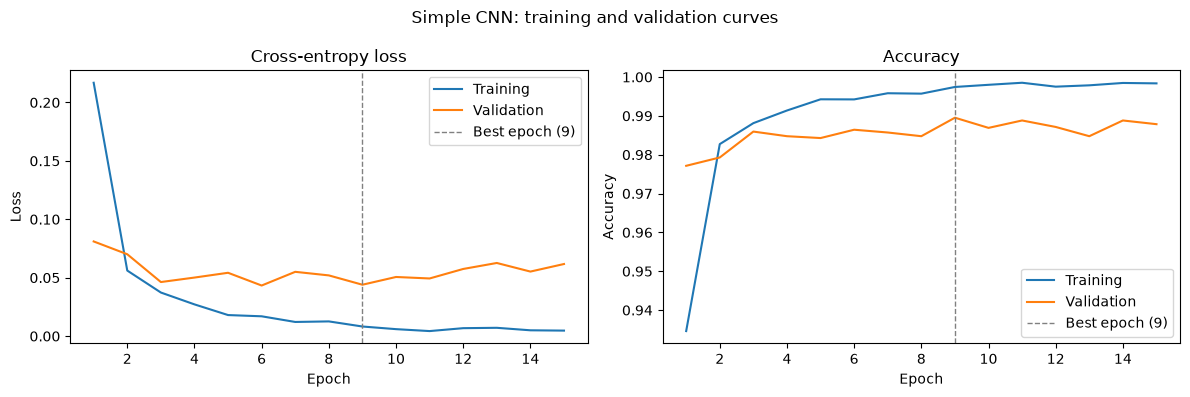

SimpleCNN best validation accuracy: 0.9895 (epoch 9)
MLP best validation accuracy:       0.9786 (epoch 12)


In [14]:
plot_history(cnn_history, "Simple CNN: training and validation curves",
             save_path=results_dir / "simple_cnn_curves.png")
print(f"SimpleCNN best validation accuracy: {cnn_history['best_val_acc']:.4f} (epoch {cnn_history['best_epoch']})")
print(f"MLP best validation accuracy:       {mlp_history['best_val_acc']:.4f} (epoch {mlp_history['best_epoch']})")

**Observations**

- The CNN reaches **0.9895** validation accuracy at epoch 9, 1.09 points above the MLP. That is well beyond the
  ±0.3 point uncertainty. In errors, the MLP misclassifies 90 of the 4,200 validation images and the CNN 44, so the
  CNN halves the error.
- The CNN overfits strongly. Training accuracy reaches 0.998, while validation loss is lowest at epoch 6 (0.0433) and
  then goes up to about 0.06. Most of the 15 epochs are spent memorising the training images.
- The CNN has more parameters than the MLP (421,642 against 235,146), and 401,536 of them are in its first dense
  layer. So this comparison alone does not prove that convolutions, and not size, explain the gain. Section 4.1
  tests this directly.

## 4. Improvements

Two questions:

1. **Is the CNN better only because it is bigger?** A control model answers this (4.1).
2. **Can regularisation reduce the CNN's overfitting?** An ablation answers this (4.2 to 4.4): each model changes
   exactly one thing from the previous one, so the effect of each change can be measured separately.

| Model | Change from the previous row | Epochs |
|---|---|---|
| SimpleCNN | (reference from section 3) | 15 |
| B: ImprovedCNN | + BatchNorm after each convolution, dropout 0.25 after each block and 0.5 in the head | 30 |
| C: ImprovedCNN + augmentation | + random rotations, shifts and zooms of the training images | 30 |
| D: C + cosine schedule | + learning rate decreasing from 0.001 towards 0 | 30 |

B, C and D all get 30 epochs. Augmentation makes each epoch harder, so it needs more epochs; giving B the same
number keeps training length out of the comparison. Because `fit` keeps the best epoch, extra epochs cannot hurt B.

### 4.1 Control: is it the size?

`SimpleCNNGAP` has the same two convolutional blocks as `SimpleCNN`, but replaces the large flatten-and-linear head
with global average pooling: each of the 64 feature maps is averaged to a single number, followed by one
Linear(64 → 10). This removes about 95% of the parameters, leaving fewer than the MLP has.

In [15]:
from digit_recognizer import ImprovedCNN, SimpleCNNGAP, make_augmentation

EPOCHS_REG = 30

set_seed(SEED)
cnn_gap = SimpleCNNGAP()
print("SimpleCNNGAP trainable parameters:", count_parameters(cnn_gap))

set_seed(SEED)
gap_train_loader, _ = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
gap_history = fit(cnn_gap, gap_train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["SimpleCNN-GAP (control)"] = {"history": gap_history, "params": count_parameters(cnn_gap)}

SimpleCNNGAP trainable parameters: 19466
Epoch  1/15 | train loss 1.6695 acc 0.4298 | val loss 1.1726 acc 0.6414
Epoch  2/15 | train loss 0.9420 acc 0.7233 | val loss 0.7546 acc 0.7721
Epoch  3/15 | train loss 0.6530 acc 0.8169 | val loss 0.5712 acc 0.8331
Epoch  4/15 | train loss 0.5067 acc 0.8594 | val loss 0.4557 acc 0.8760
Epoch  5/15 | train loss 0.4214 acc 0.8820 | val loss 0.4032 acc 0.8900
Epoch  6/15 | train loss 0.3636 acc 0.8980 | val loss 0.3311 acc 0.9090
Epoch  7/15 | train loss 0.3205 acc 0.9093 | val loss 0.3130 acc 0.9110
Epoch  8/15 | train loss 0.2890 acc 0.9173 | val loss 0.2949 acc 0.9160
Epoch  9/15 | train loss 0.2664 acc 0.9232 | val loss 0.2648 acc 0.9271
Epoch 10/15 | train loss 0.2494 acc 0.9277 | val loss 0.2341 acc 0.9376
Epoch 11/15 | train loss 0.2331 acc 0.9330 | val loss 0.2328 acc 0.9300
Epoch 12/15 | train loss 0.2207 acc 0.9349 | val loss 0.2366 acc 0.9324
Epoch 13/15 | train loss 0.2089 acc 0.9389 | val loss 0.2073 acc 0.9400
Epoch 14/15 | train los

The global-average-pooling control does **not** work. It reaches 0.9436 (237 errors), worse than the MLP. Its
training accuracy is only 0.943 at epoch 15 and its loss is still falling, so it is underfitting, not overfitting.
With only two convolutional blocks, averaging each 7 x 7 feature map into one number throws away *where* in the
image each pattern appears. Position matters for digits: a 1 and a 7 share a vertical stroke and differ in where the
other strokes are. This control therefore tests a head that is too weak, not a smaller CNN, and cannot answer the
size question.

A fairer control keeps the `SimpleCNN` architecture unchanged and only shrinks its hidden dense layer from 128
to 64 units. That gives fewer parameters than the MLP, with nothing else changed.

In [16]:
set_seed(SEED)
cnn_small = SimpleCNN(head_dim=64)
print(f"SimpleCNN with 64-unit head: {count_parameters(cnn_small):,} parameters (MLP: {count_parameters(mlp):,})")

set_seed(SEED)
small_train_loader, _ = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
small_history = fit(cnn_small, small_train_loader, val_loader, epochs=EPOCHS, device=device, lr=1e-3)
results["SimpleCNN-64 (size-matched control)"] = {"history": small_history, "params": count_parameters(cnn_small)}

SimpleCNN with 64-unit head: 220,234 parameters (MLP: 235,146)
Epoch  1/15 | train loss 0.2537 acc 0.9219 | val loss 0.0896 acc 0.9726
Epoch  2/15 | train loss 0.0620 acc 0.9815 | val loss 0.0660 acc 0.9798
Epoch  3/15 | train loss 0.0419 acc 0.9870 | val loss 0.0485 acc 0.9876
Epoch  4/15 | train loss 0.0305 acc 0.9903 | val loss 0.0565 acc 0.9821
Epoch  5/15 | train loss 0.0239 acc 0.9922 | val loss 0.0531 acc 0.9843
Epoch  6/15 | train loss 0.0191 acc 0.9939 | val loss 0.0401 acc 0.9910
Epoch  7/15 | train loss 0.0143 acc 0.9955 | val loss 0.0455 acc 0.9869
Epoch  8/15 | train loss 0.0155 acc 0.9949 | val loss 0.0506 acc 0.9867
Epoch  9/15 | train loss 0.0104 acc 0.9968 | val loss 0.0500 acc 0.9881
Epoch 10/15 | train loss 0.0093 acc 0.9969 | val loss 0.0538 acc 0.9879
Epoch 11/15 | train loss 0.0064 acc 0.9977 | val loss 0.0547 acc 0.9874
Epoch 12/15 | train loss 0.0068 acc 0.9978 | val loss 0.0573 acc 0.9857
Epoch 13/15 | train loss 0.0092 acc 0.9966 | val loss 0.0510 acc 0.9898
E

**Result of the size-matched control.** With 220,234 parameters, fewer than the MLP's 235,146, the CNN still reaches
0.9910 (38 errors against the MLP's 90). Halving its dense layer did not hurt it either: 38 errors against 44 for the
full SimpleCNN, a difference inside the uncertainty. The CNN's advantage over the MLP therefore comes from the
convolutions, not from its size.

### 4.2 Model B: BatchNorm and dropout

BatchNorm normalises the output of each convolution over the batch, which stabilises training and has a mild
regularising effect (lecture 7). Dropout switches off a random fraction of activations at every training step, so
the network cannot rely on any single neuron (lecture 5). Both behave differently in training and evaluation, which
is why `fit` switches between `model.train()` and `model.eval()`.

In [17]:
set_seed(SEED)
model_b = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
print("ImprovedCNN trainable parameters:", count_parameters(model_b))

set_seed(SEED)
b_train_loader, _ = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
b_history = fit(model_b, b_train_loader, val_loader, epochs=EPOCHS_REG, device=device, lr=1e-3)
results["B: + BatchNorm + dropout"] = {"history": b_history, "params": count_parameters(model_b)}

ImprovedCNN trainable parameters: 421738
Epoch  1/30 | train loss 0.3804 acc 0.8812 | val loss 0.0761 acc 0.9767
Epoch  2/30 | train loss 0.1485 acc 0.9558 | val loss 0.0610 acc 0.9810
Epoch  3/30 | train loss 0.1179 acc 0.9649 | val loss 0.0477 acc 0.9869
Epoch  4/30 | train loss 0.1028 acc 0.9694 | val loss 0.0476 acc 0.9857
Epoch  5/30 | train loss 0.0912 acc 0.9715 | val loss 0.0455 acc 0.9879
Epoch  6/30 | train loss 0.0831 acc 0.9747 | val loss 0.0415 acc 0.9895
Epoch  7/30 | train loss 0.0767 acc 0.9761 | val loss 0.0400 acc 0.9898
Epoch  8/30 | train loss 0.0724 acc 0.9776 | val loss 0.0408 acc 0.9898
Epoch  9/30 | train loss 0.0656 acc 0.9798 | val loss 0.0370 acc 0.9902
Epoch 10/30 | train loss 0.0638 acc 0.9798 | val loss 0.0412 acc 0.9890
Epoch 11/30 | train loss 0.0598 acc 0.9812 | val loss 0.0395 acc 0.9898
Epoch 12/30 | train loss 0.0580 acc 0.9814 | val loss 0.0384 acc 0.9902
Epoch 13/30 | train loss 0.0535 acc 0.9826 | val loss 0.0372 acc 0.9883
Epoch 14/30 | train los

### 4.3 Model C: data augmentation

Every time a training image is used, it is randomly rotated by up to ±10°, shifted by up to 10% and zoomed between
90% and 110%. The network never sees exactly the same image twice, which makes memorising harder. These changes
mimic how people actually write digits differently.

No flips are used: a mirrored digit is no longer the same digit. Rotations are kept small because a large rotation
could turn a 6 into a 9. Validation images are never augmented, so the validation score stays comparable.

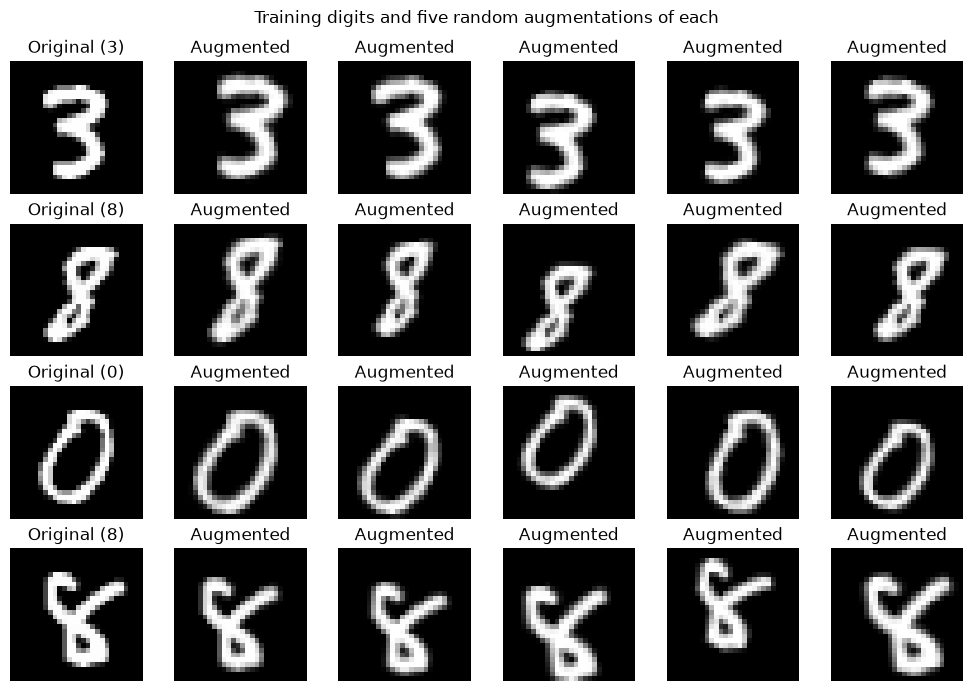

In [18]:
augment = make_augmentation(degrees=10, shift=0.1, scale=(0.9, 1.1))
display_ds = DigitDataset(X_train, y_train, mean=0.0, std=1.0, transform=augment)

set_seed(SEED)
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for row, idx in enumerate([0, 1, 2, 3]):
    axes[row, 0].imshow(X_train[idx].reshape(28, 28), cmap="gray")
    axes[row, 0].set_title(f"Original ({y_train[idx]})")
    for col in range(1, 6):
        augmented, _ = display_ds[idx]
        axes[row, col].imshow(augmented.squeeze(0), cmap="gray")
        axes[row, col].set_title("Augmented")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Training digits and five random augmentations of each")
plt.tight_layout()
plt.savefig(results_dir / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
train_aug_ds = DigitDataset(X_train, y_train, mean, std, transform=augment)
set_seed(SEED)
model_c = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
set_seed(SEED)
c_train_loader, _ = make_loaders(train_aug_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
c_history = fit(model_c, c_train_loader, val_loader, epochs=EPOCHS_REG, device=device, lr=1e-3)
results["C: B + augmentation"] = {"history": c_history, "params": count_parameters(model_c)}

Epoch  1/30 | train loss 0.7567 acc 0.7513 | val loss 0.1147 acc 0.9636
Epoch  2/30 | train loss 0.3503 acc 0.8907 | val loss 0.0623 acc 0.9802
Epoch  3/30 | train loss 0.2863 acc 0.9114 | val loss 0.0679 acc 0.9781
Epoch  4/30 | train loss 0.2490 acc 0.9217 | val loss 0.0502 acc 0.9864
Epoch  5/30 | train loss 0.2224 acc 0.9312 | val loss 0.0473 acc 0.9852
Epoch  6/30 | train loss 0.2161 acc 0.9337 | val loss 0.0439 acc 0.9871
Epoch  7/30 | train loss 0.1979 acc 0.9373 | val loss 0.0391 acc 0.9871
Epoch  8/30 | train loss 0.1836 acc 0.9429 | val loss 0.0375 acc 0.9890
Epoch  9/30 | train loss 0.1763 acc 0.9459 | val loss 0.0403 acc 0.9881
Epoch 10/30 | train loss 0.1759 acc 0.9474 | val loss 0.0366 acc 0.9888
Epoch 11/30 | train loss 0.1613 acc 0.9507 | val loss 0.0368 acc 0.9881
Epoch 12/30 | train loss 0.1588 acc 0.9525 | val loss 0.0299 acc 0.9912
Epoch 13/30 | train loss 0.1462 acc 0.9557 | val loss 0.0264 acc 0.9917
Epoch 14/30 | train loss 0.1498 acc 0.9545 | val loss 0.0278 acc

### 4.4 Model D: learning-rate schedule

A cosine schedule lowers the learning rate smoothly from 0.001 towards 0 over the 30 epochs (the scheduler used
in the Session 12 notebook). Large steps early on make fast progress; small steps at the end let the weights settle
into a minimum instead of bouncing around it.

In [20]:
set_seed(SEED)
model_d = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
set_seed(SEED)
d_train_loader, _ = make_loaders(train_aug_ds, val_ds, batch_size=128, seed=SEED)  # fresh loader: same shuffle order whatever ran before
d_history = fit(model_d, d_train_loader, val_loader, epochs=EPOCHS_REG, device=device, lr=1e-3, scheduler="cosine")
results["D: C + cosine schedule"] = {"history": d_history, "params": count_parameters(model_d)}

Epoch  1/30 | train loss 0.7567 acc 0.7513 | val loss 0.1147 acc 0.9636
Epoch  2/30 | train loss 0.3504 acc 0.8909 | val loss 0.0651 acc 0.9793
Epoch  3/30 | train loss 0.2860 acc 0.9104 | val loss 0.0747 acc 0.9779
Epoch  4/30 | train loss 0.2497 acc 0.9220 | val loss 0.0517 acc 0.9848
Epoch  5/30 | train loss 0.2207 acc 0.9312 | val loss 0.0475 acc 0.9855
Epoch  6/30 | train loss 0.2119 acc 0.9356 | val loss 0.0440 acc 0.9864
Epoch  7/30 | train loss 0.1949 acc 0.9379 | val loss 0.0394 acc 0.9881
Epoch  8/30 | train loss 0.1831 acc 0.9433 | val loss 0.0383 acc 0.9883
Epoch  9/30 | train loss 0.1745 acc 0.9470 | val loss 0.0387 acc 0.9886
Epoch 10/30 | train loss 0.1722 acc 0.9486 | val loss 0.0374 acc 0.9890
Epoch 11/30 | train loss 0.1599 acc 0.9518 | val loss 0.0362 acc 0.9883
Epoch 12/30 | train loss 0.1579 acc 0.9537 | val loss 0.0293 acc 0.9912
Epoch 13/30 | train loss 0.1424 acc 0.9567 | val loss 0.0292 acc 0.9912
Epoch 14/30 | train loss 0.1471 acc 0.9555 | val loss 0.0292 acc

### 4.5 Comparison

In [21]:
import pandas as pd

n_val = len(y_val)
rows = []
for name, res in results.items():
    h = res["history"]
    rows.append({
        "Model": name,
        "Parameters": res["params"],
        "Best val accuracy": round(h["best_val_acc"], 4),
        "Val errors (of 4,200)": round((1 - h["best_val_acc"]) * n_val),
        "Best epoch": h["best_epoch"],
        "Epochs trained": len(h["val_acc"]),
        "Training time (s)": round(h["train_time_s"]),
    })
comparison = pd.DataFrame(rows)
comparison.to_csv(results_dir / "model_comparison.csv", index=False)
comparison

,Model,Parameters,Best val accuracy,"Val errors (of 4,200)",Best epoch,Epochs trained,Training time (s)
0,MLP,235146,0.9786,90,12,15,12
1,SimpleCNN,421642,0.9895,44,9,15,80
2,SimpleCNN-GAP (control),19466,0.9436,237,14,15,79
3,SimpleCNN-64 (size-matched control),220234,0.9910,38,6,15,73
4,B: + BatchNorm + dropout,421738,0.9929,30,20,30,163
5,C: B + augmentation,421738,0.9926,31,29,30,155
6,D: C + cosine schedule,421738,0.9933,28,29,30,155


**Observations on the ablation**

- **BatchNorm and dropout clearly help** (SimpleCNN → B). Validation errors fall from 44 to 30, and the lowest
  validation loss from 0.0433 to 0.0295. The overfitting gap closes. At the end, training accuracy (0.990) is no
  longer far above validation accuracy (0.992).
- **B, C and D cannot be separated on validation.** They make 30, 31 and 28 errors. These are differences of two or
  three images, well inside the uncertainty of about ±13 images.
- **Augmentation shows no measurable gain on validation here.** It does change the training. At epoch 30, C and D
  reach only about 0.97 training accuracy, below their validation accuracy, because the augmented training images
  are harder than the clean validation images. The models are still learning, so 30 epochs probably does not show
  augmentation at its best. This is a limitation of the experiment, not evidence that augmentation is useless.
- **D ends training in the best state.** At the last epoch, D has the highest validation accuracy (0.9929 against
  0.9921 for B and 0.9905 for C) and the lowest validation loss (0.0262 against 0.0308 and 0.0306). The cosine
  schedule makes the learning rate almost zero in the last epochs, so the weights settle instead of jumping around.

**Choice for the final submission: D.** Not because its best score (0.9933) beats the others, which is inside the
uncertainty. The final models are trained on all 42,000 images, so there is no validation set left to pick the best
epoch. They have to stop at a fixed epoch, and D is the configuration that is in the best state at its last epoch.

## 5. Analysis

### 5.1 All models compared

Validation loss and accuracy per epoch for every model, on the same validation images.

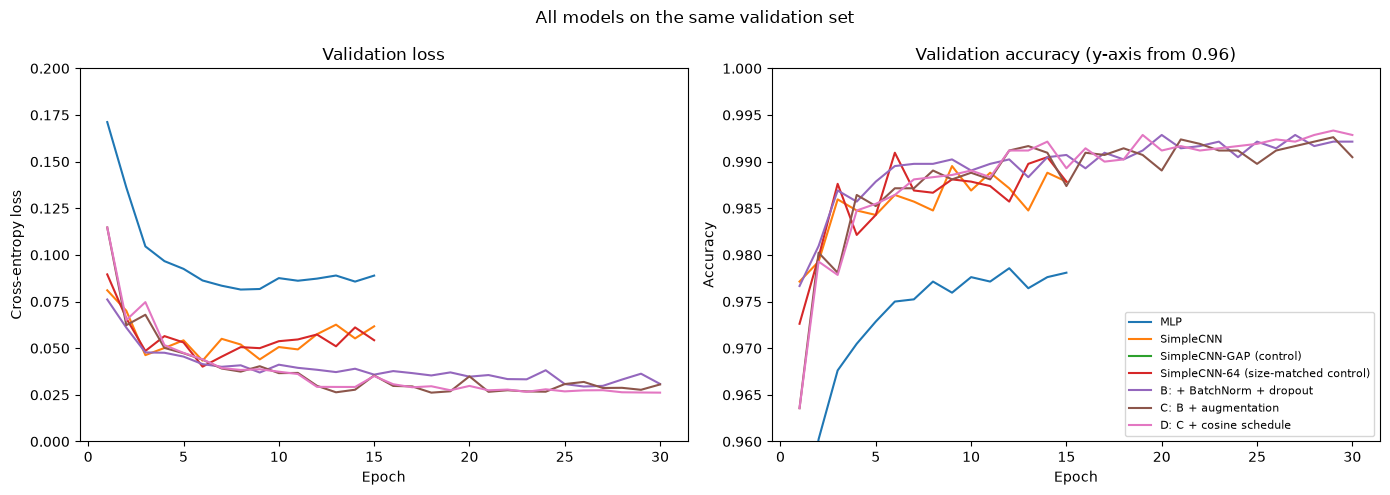

In [22]:
from digit_recognizer import plot_confusion_matrix, plot_misclassified, plot_model_comparison, predict_proba

_ = plot_model_comparison(results, save_path=results_dir / "model_comparison_curves.png")

**Observations**

- The models without regularisation (MLP, SimpleCNN, SimpleCNN-64) reach their lowest validation loss early
  (epochs 6 to 8) and then go up again while their training loss keeps falling. That is the overfitting pattern.
- B, C and D keep a low and mostly falling validation loss for all 30 epochs. The regularisation removes the
  overfitting instead of only delaying it.
- The GAP control lies outside the plotted range for most epochs (validation loss above 0.2, accuracy below 0.96).
  It never catches up with the other models, which matches the underfitting diagnosis in section 4.1.
- In accuracy, B, C and D end in the same narrow band (about 0.990 to 0.993). The differences between their curves
  are smaller than the epoch-to-epoch noise.

### 5.2 Errors of the chosen model (D)

Model D is restored to its best epoch. We predict the validation set, check that the accuracy matches the value
reported during training, and look at which digits it confuses.

Model D validation accuracy: 0.9933 (28 errors of 4200)


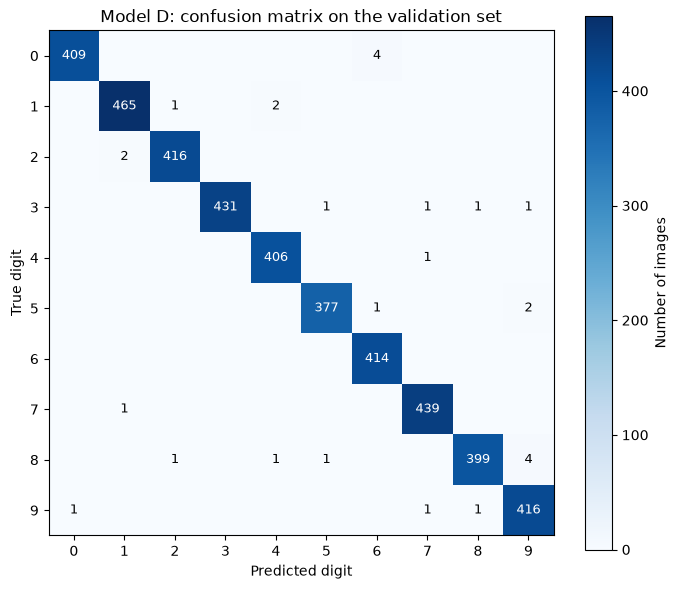

Digit 0: accuracy 0.9903, errors 4
Digit 1: accuracy 0.9936, errors 3
Digit 2: accuracy 0.9952, errors 2
Digit 3: accuracy 0.9908, errors 4
Digit 4: accuracy 0.9975, errors 1
Digit 5: accuracy 0.9921, errors 3
Digit 6: accuracy 1.0000, errors 0
Digit 7: accuracy 0.9977, errors 1
Digit 8: accuracy 0.9828, errors 7
Digit 9: accuracy 0.9928, errors 3

Most frequent confusions (true -> predicted):
  8 -> 9: 4
  0 -> 6: 4
  5 -> 9: 2
  2 -> 1: 2
  1 -> 4: 2


In [23]:
val_probs = predict_proba(model_d, val_loader, device)
val_pred = val_probs.argmax(axis=1)
val_accuracy = (val_pred == y_val).mean()
print(f"Model D validation accuracy: {val_accuracy:.4f} ({(val_pred != y_val).sum()} errors of {len(y_val)})")

matrix = plot_confusion_matrix(y_val, val_pred, "Model D: confusion matrix on the validation set",
                               save_path=results_dir / "confusion_matrix_model_d.png")

per_class_acc = matrix.diagonal() / matrix.sum(axis=1)
for digit in range(10):
    print(f"Digit {digit}: accuracy {per_class_acc[digit]:.4f}, errors {matrix[digit].sum() - matrix[digit, digit]}")

pairs = [(matrix[i, j], i, j) for i in range(10) for j in range(10) if i != j and matrix[i, j] > 0]
pairs.sort(reverse=True)
print("\nMost frequent confusions (true -> predicted):")
for count, i, j in pairs[:5]:
    print(f"  {i} -> {j}: {count}")

**Observations**

- The predicted accuracy matches the value reported during training (0.9933, 28 errors), so restoring the best
  weights and predicting work correctly.
- The errors are spread thinly over the classes. No confusion happens more than 4 times.
- 8 is the hardest digit (7 errors, 0.9828) and 6 the easiest (no errors).
- The two most frequent confusions are 8 → 9 and 0 → 6 (4 each). Both pairs share most of their shape. An 8 with a
  small or faint lower loop looks like a 9, and a 0 whose stroke continues past the top of the loop looks like a 6.

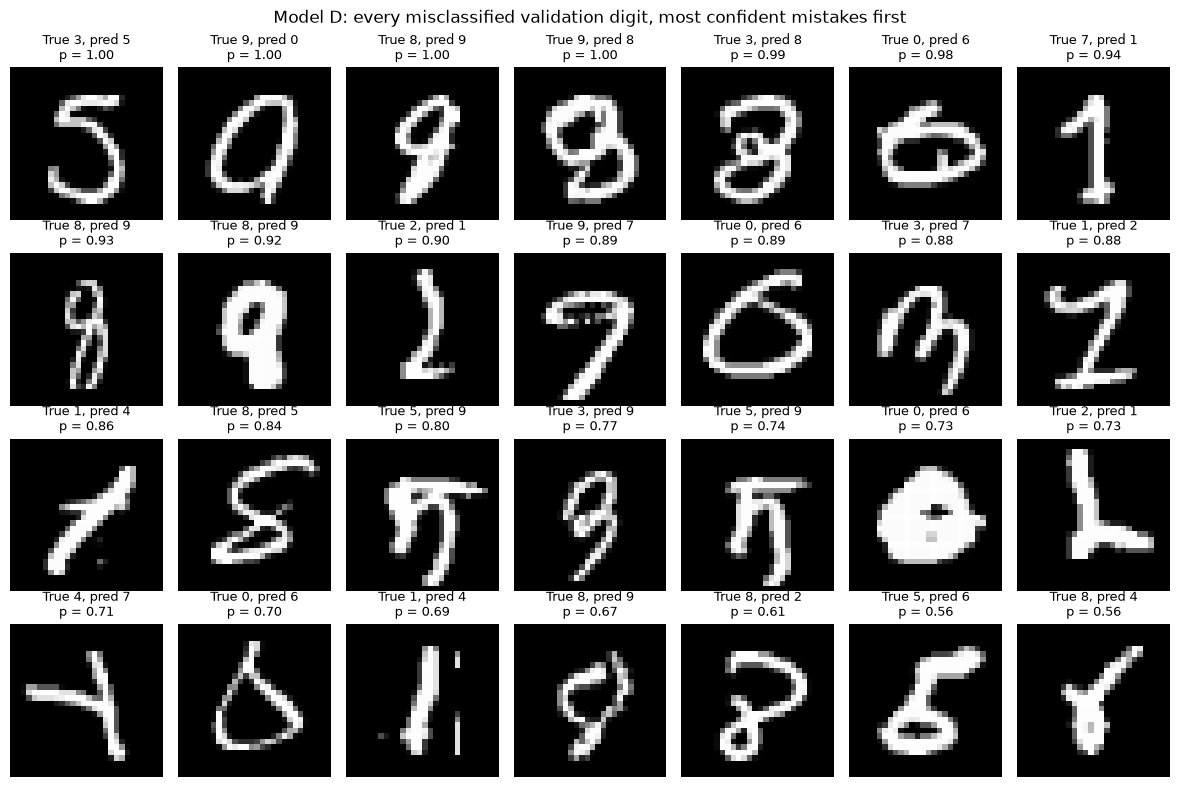

Number of misclassified validation images: 28


In [24]:
wrong = plot_misclassified(X_val, y_val, val_pred, val_probs,
                           "Model D: every misclassified validation digit, most confident mistakes first",
                           save_path=results_dir / "misclassified_model_d.png")
print("Number of misclassified validation images:", len(wrong))

### 5.3 Manual review of the 28 errors

I looked at all 28 misclassified validation images and sorted each into one category. This is a human judgement,
so it is stored in `results/misclassified_review.csv` together with each image's row in `train.csv`, so every
category can be checked against the original data.

| Category | Grid numbers | Count |
|---|---|---|
| Mislabelled in the dataset | 1, 4, 7, 8 | 4 |
| Genuinely ambiguous | 3, 5, 9, 21, 22, 27, 28 | 7 |
| 0 versus 6 or 9 (stroke past the loop, or a very short stem) | 2, 6, 12, 23 | 4 |
| Sloppy but readable | 10, 11, 16, 17, 18, 19, 20, 24, 25 | 9 |
| Clear model mistakes | 13, 14, 15, 26 | 4 |

Grid numbers follow the figure above, which is sorted from the most to the least confident mistake.

In [25]:
review = pd.read_csv(results_dir / "misclassified_review.csv")
print(review["category"].value_counts().to_string())
review

category
sloppy but readable                          9
genuinely ambiguous                          7
mislabelled in dataset                       4
0 vs 6/9 (stroke past loop or short stem)    4
clear model mistake                          4


,grid_number,train_csv_row,validation_position,true_label,predicted_label,category
0,1,24477,3193,3,5,mislabelled in dataset
1,2,37290,2690,9,0,0 vs 6/9 (stroke past loop or short stem)
2,3,5747,3760,8,9,genuinely ambiguous
3,4,37887,2468,9,8,mislabelled in dataset
4,5,8169,2638,3,8,genuinely ambiguous
5,6,34897,140,0,6,0 vs 6/9 (stroke past loop or short stem)
6,7,25946,2840,7,1,mislabelled in dataset
7,8,26421,334,8,9,mislabelled in dataset
8,9,28611,591,8,9,genuinely ambiguous
9,10,6972,3759,2,1,sloppy but readable


**Observations**

- **4 of the 28 "errors" are labelling errors in the dataset.** For example, grid image 1 (row 24,477 of `train.csv`)
  is labelled 3, but it is clearly a 5, and the model predicted 5. In these cases the model is right and the label is
  wrong. This also means no model can reach 100% on this validation set.
- **The mislabelled images are concentrated at the top of the grid.** The grid is sorted by the model's confidence,
  and 4 of the 8 most confident mistakes are label errors. When the model is very sure and still counted as wrong,
  the label is often what is wrong.
- **Only 4 of the 28 errors are clear model mistakes.** The other 24 are limits of the data (wrong labels, digits a
  person would also hesitate on) or unusual handwriting. The 0 versus 6/9 group explains the 0 → 6 confusion in the
  confusion matrix.
- I did not correct or remove the mislabelled images. Relabelling by my own judgement would change the data in a way
  the code cannot reproduce, and correcting validation labels would make the score look better than it is.

## 6. Final models and Kaggle submission

The final prediction is the average of five copies of model D, each trained on **all 42,000** labelled images
with a different seed (42 to 46).

- **All the data.** The validation set has done its job: it chose the configuration (D) and the number of epochs (30).
  Training on the 4,200 validation images as well gives the final models 11% more data.
- **No validation set left.** Nothing can pick the best epoch anymore, so every model stops after 30 epochs. That is
  why model D was chosen: it was in its best state at its last epoch.
- **Normalisation is recomputed** on all 42,000 images, because these are now the training images. The test images
  use the same mean and standard deviation.
- **An ensemble of five.** Models trained with different seeds see the data in a different order and start from
  different weights, so they make partly different mistakes. Averaging their probabilities cancels some of these
  mistakes.

### 6.1 Does averaging models help? A check on the validation set

The final ensemble cannot be validated, because it is trained on the validation images. As a check of the idea,
we average models B, C and D, which were all trained on the same training split, and compare with each alone.

In [26]:
from digit_recognizer import make_test_loader, make_train_loader, train_final, validate_submission, write_submission

check_probs = {}
for name, model in [("B", model_b), ("C", model_c), ("D", model_d)]:
    check_probs[name] = predict_proba(model, val_loader, device)
    errors = (check_probs[name].argmax(axis=1) != y_val).sum()
    print(f"Model {name} alone: {errors} errors")

average_probs = (check_probs["B"] + check_probs["C"] + check_probs["D"]) / 3
print(f"Average of B, C and D: {(average_probs.argmax(axis=1) != y_val).sum()} errors")

Model B alone: 30 errors
Model C alone: 31 errors
Model D alone: 28 errors
Average of B, C and D: 21 errors


**Observation.** The average of B, C and D makes 21 errors, against 28 to 31 for each model alone. That gain of 7 to
10 images is just inside the uncertainty of about ±13 images, so it is consistent with averaging helping but does not
prove it. The final ensemble itself cannot be validated, because it is trained on the validation images too.

### 6.2 Train the five final models

In [27]:
X_all = train_df.drop(columns="label").values
y_all = train_df["label"].values
mean_all, std_all = compute_mean_std(X_all)
print(f"Mean and std on all 42,000 images: {mean_all:.4f}, {std_all:.4f}")

full_aug_ds = DigitDataset(X_all, y_all, mean_all, std_all, transform=augment)
test_ds = DigitDataset(test_df.values, None, mean_all, std_all)
test_loader = make_test_loader(test_ds)

models_dir = results_dir / "models"
models_dir.mkdir(exist_ok=True)
FINAL_SEEDS = [42, 43, 44, 45, 46]
test_probs = []

for seed in FINAL_SEEDS:
    print(f"\n--- Final model, seed {seed} ---")
    set_seed(seed)
    final_model = ImprovedCNN(conv_dropout=0.25, head_dropout=0.5)
    set_seed(seed)
    final_loader = make_train_loader(full_aug_ds, batch_size=128, seed=seed)
    train_final(final_model, final_loader, epochs=EPOCHS_REG, device=device, lr=1e-3, scheduler="cosine")
    torch.save(final_model.state_dict(), models_dir / f"model_d_seed{seed}.pt")
    test_probs.append(predict_proba(final_model, test_loader, device))

Mean and std on all 42,000 images: 0.1310, 0.3085

--- Final model, seed 42 ---
Epoch  5/30 | train loss 0.2072 acc 0.9372
Epoch 10/30 | train loss 0.1532 acc 0.9532
Epoch 15/30 | train loss 0.1270 acc 0.9619
Epoch 20/30 | train loss 0.1062 acc 0.9695
Epoch 25/30 | train loss 0.0938 acc 0.9726
Epoch 30/30 | train loss 0.0915 acc 0.9729

--- Final model, seed 43 ---
Epoch  5/30 | train loss 0.2379 acc 0.9264
Epoch 10/30 | train loss 0.1729 acc 0.9484
Epoch 15/30 | train loss 0.1426 acc 0.9575
Epoch 20/30 | train loss 0.1225 acc 0.9632
Epoch 25/30 | train loss 0.1100 acc 0.9680
Epoch 30/30 | train loss 0.1082 acc 0.9683

--- Final model, seed 44 ---
Epoch  5/30 | train loss 0.2568 acc 0.9199
Epoch 10/30 | train loss 0.1856 acc 0.9424
Epoch 15/30 | train loss 0.1566 acc 0.9521
Epoch 20/30 | train loss 0.1370 acc 0.9580
Epoch 25/30 | train loss 0.1270 acc 0.9621
Epoch 30/30 | train loss 0.1187 acc 0.9638

--- Final model, seed 45 ---
Epoch  5/30 | train loss 0.2142 acc 0.9344
Epoch 10/30 |

### 6.3 Ensemble, checks and submission file

In [28]:
ensemble_probs = np.mean(test_probs, axis=0)
test_pred = ensemble_probs.argmax(axis=1)

for seed, probs in zip(FINAL_SEEDS, test_probs):
    agreement = (probs.argmax(axis=1) == test_pred).mean()
    print(f"Seed {seed} agrees with the ensemble on {agreement:.4f} of test images "
          f"({(probs.argmax(axis=1) != test_pred).sum()} differ)")

single_d_pred = predict_proba(model_d, test_loader, device).argmax(axis=1)
print(f"Validation-run model D agrees with the ensemble on {(single_d_pred == test_pred).mean():.4f}")

train_share = np.bincount(y_all, minlength=10) / len(y_all)
test_share = np.bincount(test_pred, minlength=10) / len(test_pred)
print("\nDigit  share in training  share in test predictions")
for digit in range(10):
    print(f"  {digit}        {train_share[digit]:.3f}               {test_share[digit]:.3f}")

Seed 42 agrees with the ensemble on 0.9968 of test images (89 differ)
Seed 43 agrees with the ensemble on 0.9966 of test images (95 differ)
Seed 44 agrees with the ensemble on 0.9970 of test images (83 differ)
Seed 45 agrees with the ensemble on 0.9970 of test images (85 differ)
Seed 46 agrees with the ensemble on 0.9973 of test images (76 differ)
Validation-run model D agrees with the ensemble on 0.9966

Digit  share in training  share in test predictions
  0        0.098               0.099
  1        0.112               0.113
  2        0.099               0.101
  3        0.104               0.100
  4        0.097               0.099
  5        0.090               0.090
  6        0.099               0.099
  7        0.105               0.103
  8        0.097               0.098
  9        0.100               0.099


In [29]:
submission_path = results_dir / "submission.csv"
submission = write_submission(test_pred, submission_path)
print("Submission valid:", validate_submission(submission_path))
submission.head()

Submission valid: True


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,0
4,5,3


**Observations**

- Each of the five final models disagrees with the ensemble on only 76 to 95 of the 28,000 test images (about 0.3%).
  These are the uncertain cases that averaging resolves.
- The final models end at 0.964 to 0.973 training accuracy. That is below 1.0 because their training images are
  augmented and dropout is active during training, not because they fail to learn.
- The predicted share of every digit on the test set is within 0.4 points of its share in the training data, so the
  ensemble does not over- or under-predict any class.
- The submission file passes every format check from the instructions.

## 7. Result

The submitted file scored **0.99232** on the Kaggle public leaderboard (username **estellearnander03**). That is
below the validation results (0.9950 for the average of B, C and D). The validation scores are slightly optimistic,
because validation was used to choose the model and the epoch, the Kaggle score has its own uncertainty, and the test
set very likely contains mislabelled images, as `train.csv` does.

Models C and D were still learning at epoch 30, so training them for longer is the most promising next step. It
should be tested on the validation set first, and the ensemble only retrained and resubmitted if validation shows
a clear gain.